# Portfolio Assessment 3
## Advanced ML and Deep Learning: Building Heating-Demand Classification
**COS40007 - Artificial Intelligence Engineering | Swinburne Vietnam**  
**Nguyen Van Tuan Kiet | 104772099 | Class identifier: COS40007**  
**Prepared: 2 November 2026 | Option 3d: ANN for non-sequential tabular data**

**Reference implementation - substantial GenAI assistance.** OpenAI Codex generated
the experimental design, code, analysis and draft explanations, and executed and
verified the computations. The supplied brief permits GenAI for brainstorming,
debugging, comments and report formatting, and explicitly prohibits whole-code
generation. This reference does not satisfy that authorship restriction merely by
disclosing assistance. Student authorship, understanding, approval for any use beyond
the permitted scope, and the in-person demonstration are not established by this file.

**GitHub repository:** [https://github.com/odmiefnf/COS40007](https://github.com/odmiefnf/COS40007)  
**Portfolio 3 code, notebook, saved models and results:** [portfolio/assessment-3](https://github.com/odmiefnf/COS40007/tree/main/portfolio/assessment-3)  
No Canvas submission has been performed.

### Acknowledgement of Country
I acknowledge the Traditional Owners of the lands on which Swinburne operates and
pay respect to Elders past and present. I recognise the continuing connections of
Aboriginal and Torres Strait Islander peoples to Country, culture and community.

## Scope and experimental decisions
Continue the **UCI Energy Efficiency** dataset selected for the replacement Portfolio 2:
768 simulated building configurations, eight inputs. Predict Lower/Middle/Higher
heating-demand bands using exactly the previous training-only Y1 tercile boundaries.
Y1 is used only to label observations; Y2 is excluded. These bands are relative
educational labels, not official energy ratings. Energy was introduced in the replacement
Portfolio 2; this is not presented as the original concrete Portfolio 1 dataset.

The exact previous 537/231 development/test row membership is preserved. Split the
537 development rows into 429 fitting and 108 stratified validation rows. All five
models train on the same 429 rows; all common encoders/scalers are fitted there only.
Five-fold training CV fits preprocessing anew within each fold. Traditional models
are selected by CV accuracy; ANN batch size is selected by validation loss. The test
set is evaluated only after configurations are fixed in this run. Because it was
already examined in Portfolio 2, it is a **reused comparison set**, not a fresh
independent final validation dataset.

Part A uses Random Forest and scikit-learn MLP. Part B uses the specified Keras ANN
architecture with batch sizes 16, 32 and 64, identical seeds and a 50-epoch ceiling.
The named categories follow the assessment: MLP is itself a neural network, so this
comparison does not establish a general classical-ML-versus-neural-network divide.

In [1]:
# AI-assisted: full implementation and experimental design by OpenAI Codex.
import os, sys, json, hashlib, pickle, time, warnings
from pathlib import Path
os.environ.setdefault('KERAS_BACKEND', 'torch')
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '-1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, keras, torch
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from scipy.stats import binomtest
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
keras.utils.set_random_seed(42)
ROOT = Path.cwd()
assert (ROOT / 'data/energy_data.csv').exists(), 'Run notebook from its containing folder.'
OUT, MODELS = ROOT / 'output', ROOT / 'models'
OUT.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.facecolor': 'white'})
SEED = 42
CLASS_NAMES = ['Lower', 'Middle', 'Higher']
def savefig(name):
    plt.savefig(OUT / name, dpi=180, bbox_inches='tight'); plt.show(); plt.close()
versions = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'keras': keras.__version__, 'torch': torch.__version__,
            'backend': keras.backend.backend(), 'device': 'CPU'}
print(json.dumps(versions, indent=2))

{
  "python": "3.11.9",
  "numpy": "2.4.6",
  "pandas": "2.3.3",
  "scikit-learn": "1.7.2",
  "keras": "3.12.0",
  "torch": "2.14.1+cu130",
  "backend": "torch",
  "device": "CPU"
}


## A.1 - Load, audit and define the target
The included CSV is byte-for-byte identical to the Portfolio 2 analysis source.
X1 relative compactness; X2 surface area; X3 wall area; X4 roof area; X5 overall height;
X6 orientation; X7 glazing area; X8 glazing-area distribution. Orientation and glazing
distribution are nominal, so one-hot encoding avoids inventing ordinal distances.
The six numerical inputs are standardised. No temporal ordering exists; an LSTM or
CNN would impose an unsupported sequence or image structure.

In [2]:
source = ROOT / 'data/energy_data.csv'
digest = hashlib.sha256(source.read_bytes()).hexdigest()
assert digest == '483904d33ab6db8bb0d1791d81410c18567c6b967035325a844de8ca97046ddc'
raw = pd.read_csv(source)
assert raw.shape == (768, 10)
assert raw.isna().sum().sum() == 0
assert np.isfinite(raw.to_numpy()).all()
assert raw.duplicated().sum() == 0
feature_names = ['relative_compactness','surface_area','wall_area','roof_area',
                 'overall_height','orientation','glazing_area','glazing_distribution']
X = raw.loc[:, ['X'+str(i) for i in range(1,9)]].copy()
X.columns = feature_names
split = pd.read_csv(ROOT / 'data/pa2_split_manifest.csv').set_index('source_row_id')
assert sorted(split.index.tolist()) == list(range(len(raw)))
development_ids = split.index[split.partition == 'train'].to_numpy()
test_ids = split.index[split.partition == 'test'].to_numpy()
assert len(development_ids) == 537 and len(test_ids) == 231
cutoffs = np.quantile(raw.loc[development_ids, 'Y1'], [1/3, 2/3])
np.testing.assert_allclose(cutoffs, [14.463333333333333, 28.406666666666666])
y = pd.Series(np.digitize(raw.Y1, cutoffs, right=True), index=raw.index, name='demand_class')
fit_ids, val_ids = train_test_split(development_ids, test_size=.2, random_state=SEED,
                                   stratify=y.loc[development_ids])
assert not (set(fit_ids) & set(val_ids) or set(development_ids) & set(test_ids))
X_fit, X_val, X_test = X.loc[fit_ids], X.loc[val_ids], X.loc[test_ids]
y_fit, y_val, y_test = y.loc[fit_ids], y.loc[val_ids], y.loc[test_ids]
partition = pd.Series('test', index=raw.index)
partition.loc[fit_ids] = 'fit'; partition.loc[val_ids] = 'validation'
manifest = pd.DataFrame({'source_row_id': raw.index, 'partition': partition,
                         'pa2_partition': split.partition, 'class': y})
manifest.to_csv(OUT/'split_manifest.csv', index=False)
counts = pd.crosstab(partition, y).reindex(['fit','validation','test']).rename(columns=dict(enumerate(CLASS_NAMES)))
counts.to_csv(OUT/'class_counts.csv')
print('Source SHA256:', digest)
print('Raw shape:', raw.shape, '| Missing: 0 | Duplicate rows: 0')
print('Fixed class thresholds:', cutoffs)
print('Input shapes: fit', X_fit.shape, 'validation', X_val.shape, 'test', X_test.shape)
display(counts)
display(X_fit.describe().round(3))

Source SHA256: 483904d33ab6db8bb0d1791d81410c18567c6b967035325a844de8ca97046ddc
Raw shape: (768, 10) | Missing: 0 | Duplicate rows: 0
Fixed class thresholds: [14.46333333 28.40666667]
Input shapes: fit (429, 8) validation (108, 8) test (231, 8)


demand_class,Lower,Middle,Higher
row_0,,,
fit,143,143,143
validation,36,36,36
test,67,76,88


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_distribution
count,429.000,429.000,429.000,429.000,429.000,429.000,429.000,429.000
mean,0.759,675.549,319.699,177.925,5.205,3.497,0.231,2.825
std,0.104,87.305,43.737,44.935,1.751,1.114,0.134,1.571
min,0.620,514.500,245.000,110.250,3.500,2.000,0.000,0.000
25%,0.660,612.500,294.000,147.000,3.500,3.000,0.100,2.000
50%,0.740,686.000,318.500,220.500,3.500,3.000,0.250,3.000
75%,0.820,759.500,343.000,220.500,7.000,4.000,0.400,4.000
max,0.980,808.500,416.500,220.500,7.000,5.000,0.400,5.000


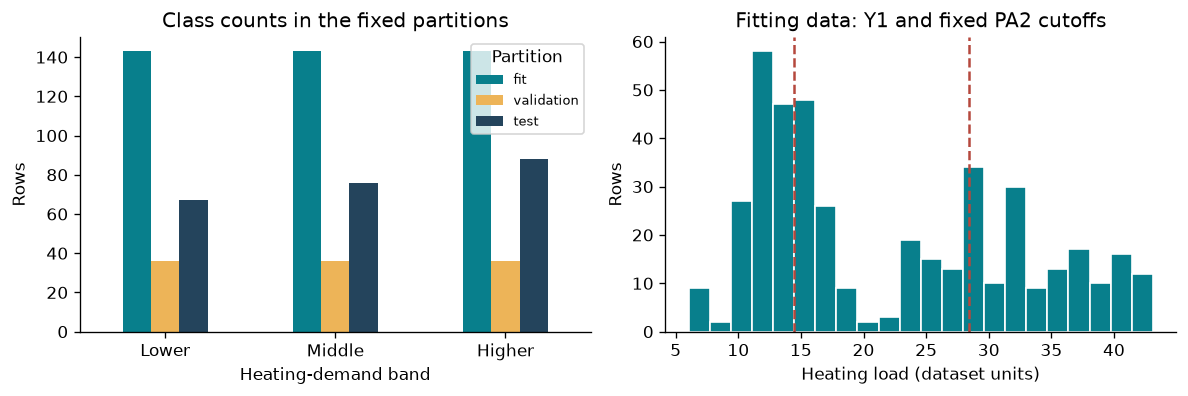

Fitting-only correlations with continuous heating load:


roof_area              -0.868
surface_area           -0.663
glazing_area            0.312
wall_area               0.460
relative_compactness    0.627
overall_height          0.890
dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
counts.T.plot.bar(ax=axes[0], color=['#087f8c','#edb458','#24445c'], rot=0)
axes[0].set(title='Class counts in the fixed partitions', xlabel='Heating-demand band', ylabel='Rows')
axes[0].legend(title='Partition', fontsize=8)
axes[1].hist(raw.loc[fit_ids,'Y1'], bins=22, color='#087f8c', edgecolor='white')
for cutoff in cutoffs: axes[1].axvline(cutoff, color='#b5483d', linestyle='--')
axes[1].set(title='Fitting data: Y1 and fixed PA2 cutoffs', xlabel='Heating load (dataset units)', ylabel='Rows')
fig.tight_layout(); savefig('01_data_and_classes.png')
numeric = [f for f in feature_names if f not in ['orientation','glazing_distribution']]
categorical = ['orientation','glazing_distribution']
correlations = X_fit[numeric].corrwith(raw.loc[fit_ids,'Y1']).sort_values()
correlations.to_csv(OUT/'fitting_correlations.csv', header=['correlation_with_Y1'])
print('Fitting-only correlations with continuous heating load:')
display(correlations.round(3))

## A.2 - Common preprocessing and leakage control
The development/test split is inherited, then a stratified 20% validation split is
reserved from development. Scaling statistics and one-hot categories come from fitting
rows only. The output is a 2D (samples, encoded features) float32 array. Validation
data are supplied explicitly rather than relying on a last-rows validation split.
The target cutoffs remain the PA2 task definition; they are not re-estimated per model.

In [4]:
def make_preprocessor():
    return ColumnTransformer([
        ('numeric', StandardScaler(), numeric),
        ('nominal', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ], verbose_feature_names_out=False)
preprocessor = make_preprocessor()
A_fit = preprocessor.fit_transform(X_fit).astype('float32')
A_val = preprocessor.transform(X_val).astype('float32')
A_test = preprocessor.transform(X_test).astype('float32')
encoded_names = preprocessor.get_feature_names_out().tolist()
assert A_fit.ndim == 2 and A_fit.shape[1] == 16
np.testing.assert_allclose(A_fit[:,:6].mean(axis=0), 0, atol=1e-6)
np.testing.assert_allclose(preprocessor.named_transformers_['numeric'].mean_, X_fit[numeric].mean())
with open(MODELS/'ann_preprocessor.pkl', 'wb') as f: pickle.dump(preprocessor,f)
print('Encoded shapes:', A_fit.shape, A_val.shape, A_test.shape)
print('Feature order:', encoded_names)
print('Scaler fitted on exactly', len(fit_ids), 'rows; neither validation nor test rows used.')

Encoded shapes: (429, 16) (108, 16) (231, 16)
Feature order: ['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height', 'glazing_area', 'orientation_2', 'orientation_3', 'orientation_4', 'orientation_5', 'glazing_distribution_0', 'glazing_distribution_1', 'glazing_distribution_2', 'glazing_distribution_3', 'glazing_distribution_4', 'glazing_distribution_5']
Scaler fitted on exactly 429 rows; neither validation nor test rows used.


## A.3 - Random Forest and scikit-learn MLP
Both pipelines consume the same eight source features and encode/scale inside each
CV fold. The Random Forest averages 300 bootstrap trees; depth and minimum leaf size
control complexity. The MLP uses ReLU, Adam, L2 regularisation and an internal 10%
early-stopping split. External validation/test rows are not used for these fits.
Four configurations per family use the same stratified five folds. Grid-search CV is
used for selection and is mildly optimistic as an estimate of the selected procedure;
it is not nested CV. Report the fold standard deviation rather than a fabricated CI.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
specs = {
    'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
                      {'model__max_depth':[None,8], 'model__min_samples_leaf':[1,2]}),
    'sklearn MLP': (MLPClassifier(activation='relu', solver='adam', max_iter=800,
                       early_stopping=True, validation_fraction=.1, n_iter_no_change=25,
                       random_state=SEED),
                    {'model__hidden_layer_sizes':[(32,),(64,32)], 'model__alpha':[.001,.01]})
}
traditional, traditional_cv, fitting_warnings = {}, [], []
for name, (estimator, grid) in specs.items():
    started = time.perf_counter()
    pipe = Pipeline([('prepare', make_preprocessor()), ('model', estimator)])
    search = GridSearchCV(pipe, grid, scoring={'accuracy':'accuracy','weighted_f1':'f1_weighted'},
                          refit='accuracy', cv=cv, n_jobs=1, error_score='raise')
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        search.fit(X_fit, y_fit)
    fitting_warnings += [name+': '+str(w.message) for w in caught]
    traditional[name] = search.best_estimator_
    idx = search.best_index_
    row = {'model':name, 'cv_accuracy':search.best_score_,
           'cv_accuracy_sd':search.cv_results_['std_test_accuracy'][idx],
           'cv_weighted_f1':search.cv_results_['mean_test_weighted_f1'][idx],
           'fit_seconds':time.perf_counter()-started, 'best_parameters':str(search.best_params_)}
    traditional_cv.append(row)
    pd.DataFrame(search.cv_results_).to_csv(OUT/(name.lower().replace(' ','_')+'_cv_grid.csv'),index=False)
    with open(MODELS/(name.lower().replace(' ','_')+'.pkl'),'wb') as f: pickle.dump(search.best_estimator_,f)
    print(name, search.best_params_, '| CV accuracy:', round(search.best_score_,4))
cv_table = pd.DataFrame(traditional_cv).set_index('model')
cv_table.to_csv(OUT/'traditional_cv.csv')
best_traditional = cv_table.cv_accuracy.idxmax()
print('Traditional model selected by training CV:',best_traditional)
print('Captured fitting warnings:', fitting_warnings or 'none')
display(cv_table.round(4))

Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 1} | CV accuracy: 0.9184


sklearn MLP {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32)} | CV accuracy: 0.7879
Traditional model selected by training CV: Random Forest
Captured fitting warnings: none


,cv_accuracy,cv_accuracy_sd,cv_weighted_f1,fit_seconds,best_parameters
model,,,,,
Random Forest,0.9184,0.0129,0.9175,5.9474,"{'model__max_depth': None, 'model__min_samples..."
sklearn MLP,0.7879,0.0538,0.7695,1.3569,"{'model__alpha': 0.01, 'model__hidden_layer_si..."


## B.1-B.2 - ANN data and exact architecture
Use the identical 429/108/231 rows and the same fitted preprocessing. The specified
network is **16 inputs -> Dense(64, ReLU) -> Dropout(0.2) -> Dense(32, ReLU) ->
Dropout(0.2) -> Dense(16, ReLU) -> Dense(3, Softmax)**. Sparse categorical
crossentropy matches integer class labels 0, 1 and 2. Adam starts at learning rate
0.001. The parameter count is 3,747. Dropout is active during training and inactive
during prediction. Keras 3 runs on the installed PyTorch CPU backend; this is a real
Keras model, saved in both native .keras and required .h5 formats.

In [6]:
def build_ann(input_dim, seed=SEED):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,), name='tabular_features'),
        keras.layers.Dense(64, activation='relu', name='dense_64'),
        keras.layers.Dropout(.2, name='dropout_1'),
        keras.layers.Dense(32, activation='relu', name='dense_32'),
        keras.layers.Dropout(.2, name='dropout_2'),
        keras.layers.Dense(16, activation='relu', name='dense_16'),
        keras.layers.Dense(3, activation='softmax', name='demand_band')
    ], name='heating_demand_ann')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model
prototype = build_ann(A_fit.shape[1])
prototype.summary()
assert prototype.count_params() == 3747

Model: "heating_demand_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_64 (Dense)                │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ demand_band (Dense)             │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,747 (14.64 KB)

 Trainable params: 3,747 (14.64 KB)

 Non-trainable params: 0 (0.00 B)

## B.3 - Controlled training experiment
Batch sizes 16, 32 and 64 are the only changed hyperparameter. Each run starts from
the same seed; batch size also changes the number of optimiser updates per epoch.
Maximum 50 epochs, EarlyStopping(val_loss, patience=10, restore_best_weights=True),
ReduceLROnPlateau(val_loss, factor=0.5, patience=5) and ModelCheckpoint(save_best_only=True).
Save history including epochs 10 and 25 when reached. This documents progress from
10 toward 50 epochs without using test performance to choose duration. Select the
ANN by lowest validation crossentropy; do not select by test accuracy.

In [7]:
ann_models, histories, ann_validation, checkpoints = {}, {}, [], []
class Milestone(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch+1 in [10,25,50]:
            print('Epoch',epoch+1, {k:round(float(v),4) for k,v in (logs or {}).items()})
for batch in [16,32,64]:
    name = 'ANN batch '+str(batch)
    model = build_ann(A_fit.shape[1])
    started = time.perf_counter()
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=5, min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(str(MODELS/f'ann_batch{batch}.keras'),monitor='val_loss',save_best_only=True),
        keras.callbacks.CSVLogger(str(OUT/f'ann_batch{batch}_epochs.csv')), Milestone()]
    history = model.fit(A_fit, y_fit.to_numpy(), validation_data=(A_val,y_val.to_numpy()),
                        batch_size=batch, epochs=50, callbacks=callbacks, shuffle=True, verbose=0)
    # Load the exact minimum-validation-loss checkpoint, not the final epoch.
    model = keras.models.load_model(MODELS/f'ann_batch{batch}.keras')
    model.save(MODELS/f'ann_batch{batch}.h5')
    histories[name] = {k:[float(v) for v in values] for k,values in history.history.items()}
    with open(MODELS/f'ann_batch{batch}_history.pkl','wb') as f: pickle.dump(histories[name],f)
    val_loss, val_accuracy = model.evaluate(A_val,y_val.to_numpy(),verbose=0)
    best_epoch = int(np.argmin(histories[name]['val_loss'])+1)
    ann_validation.append({'model':name,'batch_size':batch,'epochs_run':len(history.epoch),
                           'best_epoch':best_epoch,'validation_loss':val_loss,
                           'validation_accuracy':val_accuracy,'fit_seconds':time.perf_counter()-started})
    ann_models[name] = model
ann_validation = pd.DataFrame(ann_validation).set_index('model')
ann_validation.to_csv(OUT/'ann_validation.csv')
best_ann = ann_validation.validation_loss.idxmin()
print('ANN selected using validation loss:',best_ann)
display(ann_validation.round(4))

Epoch 10 {'accuracy': 0.8089, 'loss': 0.3928, 'val_accuracy': 0.8611, 'val_loss': 0.3508, 'learning_rate': 0.001}


Epoch 25 {'accuracy': 0.8322, 'loss': 0.3288, 'val_accuracy': 0.8611, 'val_loss': 0.3402, 'learning_rate': 0.0005}


Epoch 10 {'accuracy': 0.7809, 'loss': 0.4501, 'val_accuracy': 0.8426, 'val_loss': 0.3927, 'learning_rate': 0.001}


Epoch 25 {'accuracy': 0.8298, 'loss': 0.3444, 'val_accuracy': 0.8611, 'val_loss': 0.3466, 'learning_rate': 0.001}


Epoch 10 {'accuracy': 0.7599, 'loss': 0.5354, 'val_accuracy': 0.8704, 'val_loss': 0.4686, 'learning_rate': 0.001}


Epoch 25 {'accuracy': 0.8042, 'loss': 0.3831, 'val_accuracy': 0.8611, 'val_loss': 0.3554, 'learning_rate': 0.001}


Epoch 50 {'accuracy': 0.8485, 'loss': 0.3217, 'val_accuracy': 0.8611, 'val_loss': 0.3453, 'learning_rate': 0.0005}
ANN selected using validation loss: ANN batch 16


,batch_size,epochs_run,best_epoch,validation_loss,validation_accuracy,fit_seconds
model,,,,,,
ANN batch 16,16,33,23,0.3220,0.8611,6.8098
ANN batch 32,32,44,34,0.3368,0.8611,4.8409
ANN batch 64,64,50,49,0.3432,0.8611,3.2994


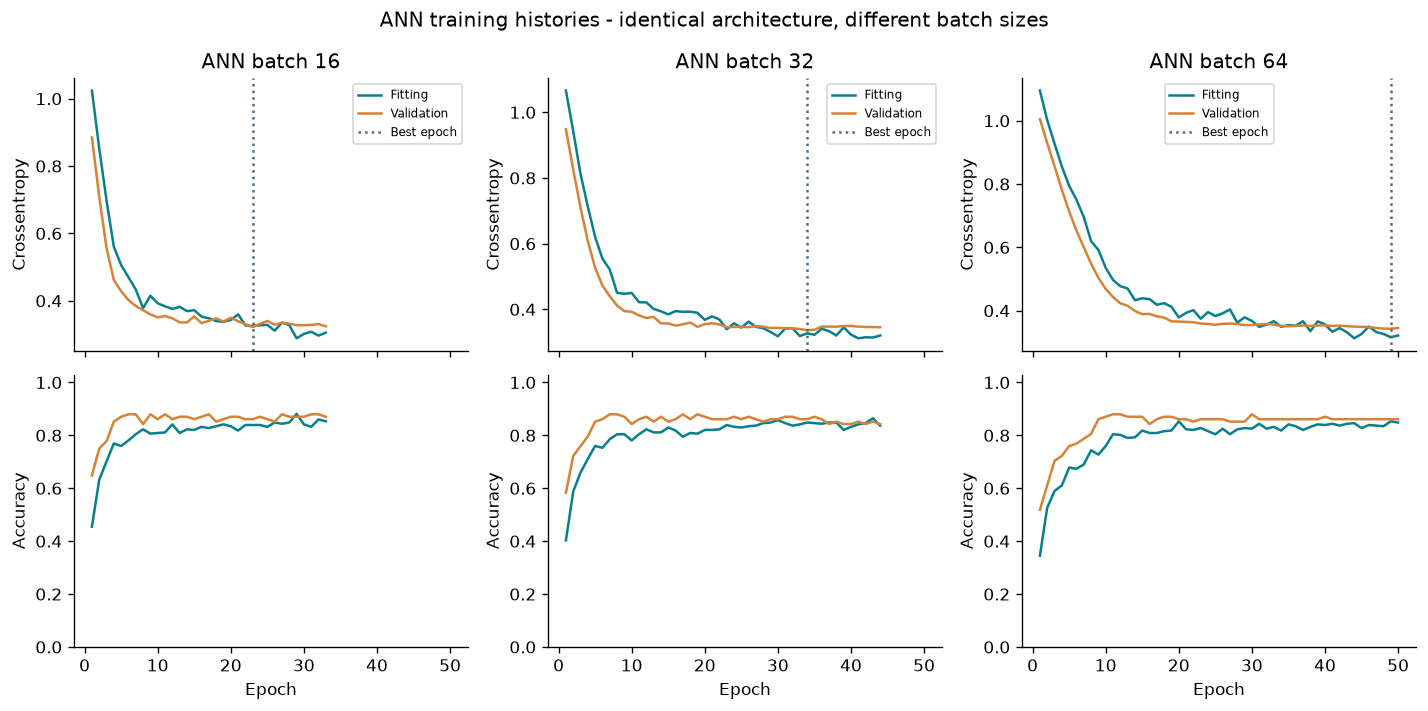

In [8]:
fig,axes=plt.subplots(2,3,figsize=(12,6),sharex=True)
for col,(name,h) in enumerate(histories.items()):
    epochs=np.arange(1,len(h['loss'])+1)
    axes[0,col].plot(epochs,h['loss'],label='Fitting',color='#087f8c')
    axes[0,col].plot(epochs,h['val_loss'],label='Validation',color='#d78337')
    axes[0,col].axvline(ann_validation.loc[name,'best_epoch'],ls=':',color='#526879',label='Best epoch')
    axes[0,col].set(title=name,ylabel='Crossentropy')
    axes[1,col].plot(epochs,h['accuracy'],label='Fitting',color='#087f8c')
    axes[1,col].plot(epochs,h['val_accuracy'],label='Validation',color='#d78337')
    axes[1,col].set(xlabel='Epoch',ylabel='Accuracy',ylim=(0,1.03))
    axes[0,col].legend(fontsize=7)
fig.suptitle('ANN training histories - identical architecture, different batch sizes')
fig.tight_layout(); savefig('02_ann_learning_curves.png')

## A.4-A.5 and B.4 - Fixed comparison-set evaluation
All configurations are now fixed. Accuracy and weighted F1 meet the classification
brief; macro F1 makes unequal class performance visible. Crossentropy evaluates
probability quality. Traditional CV values are not invented for ANN models. ANN
validation accuracy is not described as cross-validation. Bootstrap intervals below
are descriptive row-level intervals, conditional on the fitted model and shared
geometries; they do not measure uncertainty for entirely new building shapes.

In [9]:
all_models = {**traditional,**ann_models}
rows, predictions, probabilities, validation_rows = [],{}, {}, []
for name,model in all_models.items():
    is_ann = name.startswith('ANN')
    start=time.perf_counter()
    prob = model.predict(A_test,verbose=0) if is_ann else model.predict_proba(X_test)
    seconds=time.perf_counter()-start
    pred=prob.argmax(axis=1)
    val_prob=model.predict(A_val,verbose=0) if is_ann else model.predict_proba(X_val)
    fit_prob=model.predict(A_fit,verbose=0) if is_ann else model.predict_proba(X_fit)
    predictions[name], probabilities[name] = pred,prob
    val_acc=accuracy_score(y_val,val_prob.argmax(axis=1))
    val_ce=log_loss(y_val,val_prob,labels=[0,1,2])
    validation_rows.append({'model':name,'accuracy':val_acc,'loss':val_ce})
    rows.append({'model':name,'type':'Deep Learning' if is_ann else 'Traditional ML',
        'test_accuracy':accuracy_score(y_test,pred),
        'test_weighted_f1':f1_score(y_test,pred,average='weighted'),
        'test_macro_f1':f1_score(y_test,pred,average='macro'),
        'test_loss':log_loss(y_test,prob,labels=[0,1,2]),
        'fit_accuracy':accuracy_score(y_fit,fit_prob.argmax(axis=1)),
        'validation_accuracy':val_acc,'validation_loss':val_ce,
        'cv_accuracy':cv_table.loc[name,'cv_accuracy'] if not is_ann else np.nan,
        'cv_accuracy_sd':cv_table.loc[name,'cv_accuracy_sd'] if not is_ann else np.nan,
        'predict_seconds_231_rows':seconds})
results=pd.DataFrame(rows).set_index('model')
results.to_csv(OUT/'master_results.csv')
selected_by_validation = pd.DataFrame(validation_rows).sort_values(['accuracy','loss'],ascending=[False,True]).iloc[0]['model']
observed_test_best = results.sort_values(['test_accuracy','test_weighted_f1'],ascending=False).index[0]
baseline=DummyClassifier(strategy='most_frequent').fit(X_fit,y_fit)
baseline_accuracy=accuracy_score(y_test,baseline.predict(X_test))
print('Validation-selected overall candidate:',selected_by_validation)
print('Observed comparison-set leader (descriptive):',observed_test_best)
print('Majority-class comparison-set baseline:',round(baseline_accuracy,4))
display(results.round(4))
prediction_table=pd.DataFrame({'source_row_id':test_ids,'truth':y_test.to_numpy()})
for name in all_models:
    prediction_table[name]=predictions[name]
    for j in range(3): prediction_table[name+' probability '+str(j)]=probabilities[name][:,j]
prediction_table.to_csv(OUT/'holdout_predictions.csv',index=False)

Validation-selected overall candidate: Random Forest
Observed comparison-set leader (descriptive): Random Forest
Majority-class comparison-set baseline: 0.29


,type,test_accuracy,test_weighted_f1,test_macro_f1,test_loss,fit_accuracy,validation_accuracy,validation_loss,cv_accuracy,cv_accuracy_sd,predict_seconds_231_rows
model,,,,,,,,,,,
Random Forest,Traditional ML,0.9307,0.9300,0.9298,0.1876,1.0000,0.9444,0.2109,0.9184,0.0129,0.0140
sklearn MLP,Traditional ML,0.8268,0.8222,0.8232,0.4279,0.8462,0.8704,0.4256,0.7879,0.0538,0.0021
ANN batch 16,Deep Learning,0.8615,0.8585,0.8593,0.3224,0.8695,0.8611,0.3220,NaN,NaN,0.0210
ANN batch 32,Deep Learning,0.8268,0.8238,0.8244,0.3345,0.8578,0.8611,0.3368,NaN,NaN,0.0206
ANN batch 64,Deep Learning,0.8355,0.8333,0.8340,0.3345,0.8555,0.8611,0.3432,NaN,NaN,0.0205


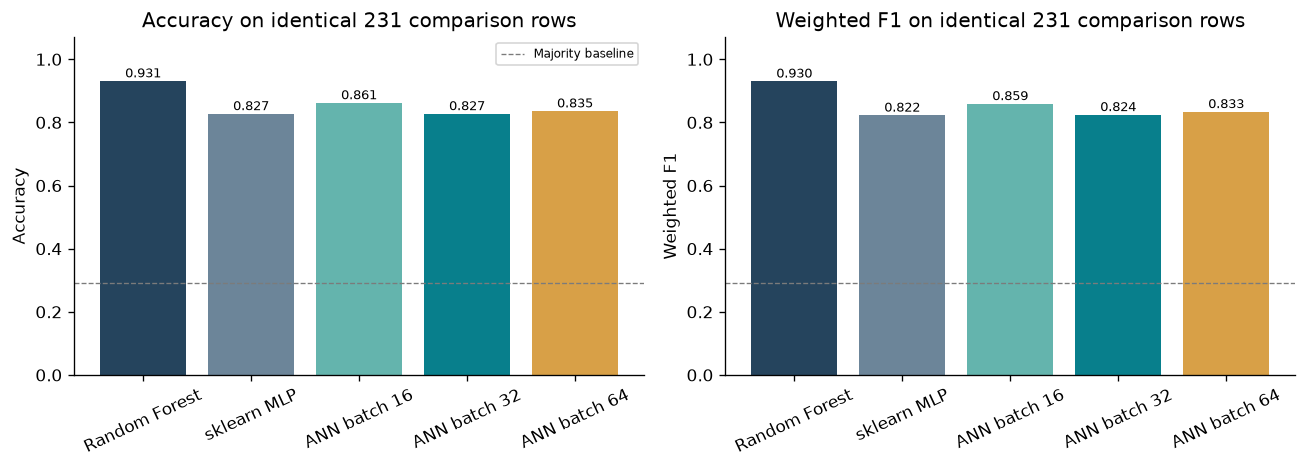

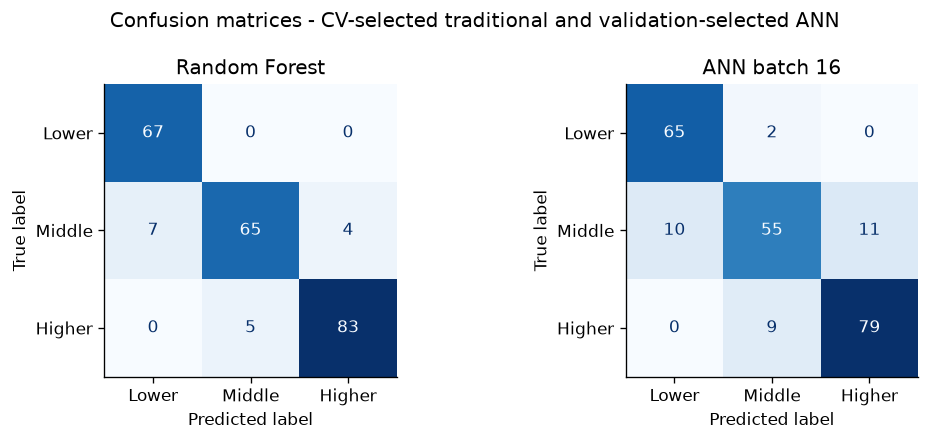

CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

       Lower     0.9054    1.0000    0.9504        67
      Middle     0.9286    0.8553    0.8904        76
      Higher     0.9540    0.9432    0.9486        88

    accuracy                         0.9307       231
   macro avg     0.9293    0.9328    0.9298       231
weighted avg     0.9315    0.9307    0.9300       231

CLASSIFICATION REPORT: ANN batch 16
              precision    recall  f1-score   support

       Lower     0.8667    0.9701    0.9155        67
      Middle     0.8333    0.7237    0.7746        76
      Higher     0.8778    0.8977    0.8876        88

    accuracy                         0.8615       231
   macro avg     0.8593    0.8639    0.8593       231
weighted avg     0.8599    0.8615    0.8585       231



In [10]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
colors=['#25445d','#6c8599','#64b4ad','#087f8c','#d8a047']
for ax,metric,title in zip(axes,['test_accuracy','test_weighted_f1'],['Accuracy','Weighted F1']):
    bars=ax.bar(results.index,results[metric],color=colors)
    for b,value in zip(bars,results[metric]): ax.text(b.get_x()+b.get_width()/2,value+.012,f'{value:.3f}',ha='center',fontsize=8)
    ax.set(title=title+' on identical 231 comparison rows',ylabel=title,ylim=(0,1.07))
    ax.tick_params(axis='x',labelrotation=25)
    ax.axhline(baseline_accuracy,ls='--',color='#7b7b7b',lw=.8,label='Majority baseline' if metric=='test_accuracy' else None)
axes[0].legend(fontsize=7)
fig.tight_layout(); savefig('03_master_comparison.png')
fig,axes=plt.subplots(1,2,figsize=(9,3.7))
for ax,name in zip(axes,[best_traditional,best_ann]):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[name],display_labels=CLASS_NAMES,
        ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(name)
fig.suptitle('Confusion matrices - CV-selected traditional and validation-selected ANN')
fig.tight_layout(); savefig('04_confusion_matrices.png')
for name in [best_traditional,best_ann]:
    print('CLASSIFICATION REPORT:',name)
    print(classification_report(y_test,predictions[name],target_names=CLASS_NAMES,digits=4))
    pd.DataFrame(classification_report(y_test,predictions[name],target_names=CLASS_NAMES,
        output_dict=True)).T.to_csv(OUT/(name.lower().replace(' ','_')+'_classification_report.csv'))

ANN minus traditional accuracy: -0.06926406926406925
Paired row bootstrap 95% interval: [-0.11688312 -0.02164502]
Discordant counts ANN-only/traditional-only: 9 25 | exact McNemar p: 0.00904118549078703
Interpretation: descriptive on reused rows; no independence across geometries is assumed for deployment.


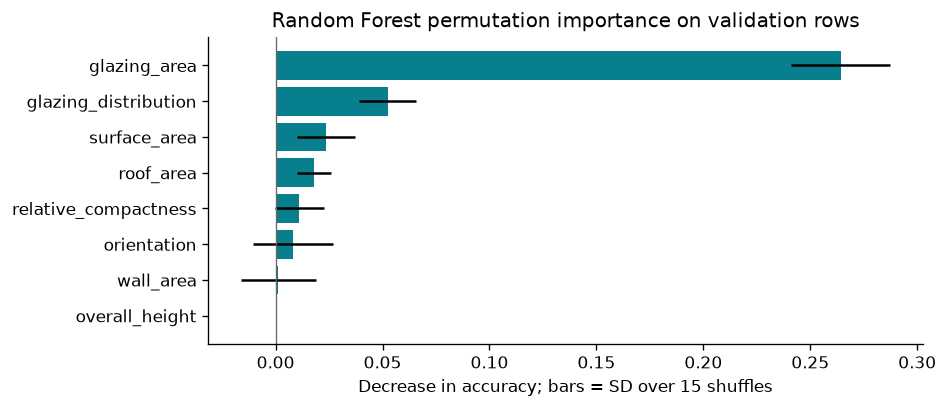

Correlated geometry predictors can mask one another; these are predictive associations, not causal effects.


In [11]:
rng=np.random.default_rng(SEED)
boot=[]
truth=y_test.to_numpy()
for _ in range(2000):
    ids=rng.integers(0,len(truth),len(truth))
    boot.append(np.mean(predictions[best_ann][ids]==truth[ids])-np.mean(predictions[best_traditional][ids]==truth[ids]))
ann_correct=predictions[best_ann]==truth
ml_correct=predictions[best_traditional]==truth
b=int(np.sum(ann_correct & ~ml_correct)); c=int(np.sum(~ann_correct & ml_correct))
paired_ci=np.quantile(boot,[.025,.975])
paired_p=binomtest(b,b+c,.5).pvalue if b+c else 1.0
print('ANN minus traditional accuracy:',results.loc[best_ann,'test_accuracy']-results.loc[best_traditional,'test_accuracy'])
print('Paired row bootstrap 95% interval:',paired_ci)
print('Discordant counts ANN-only/traditional-only:',b,c,'| exact McNemar p:',paired_p)
print('Interpretation: descriptive on reused rows; no independence across geometries is assumed for deployment.')
perm=permutation_importance(traditional['Random Forest'],X_val,y_val,n_repeats=15,random_state=SEED,scoring='accuracy')
importance=pd.DataFrame({'feature':feature_names,'accuracy_drop':perm.importances_mean,'sd':perm.importances_std}).sort_values('accuracy_drop')
importance.to_csv(OUT/'rf_validation_permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(8,3.5))
ax.barh(importance.feature,importance.accuracy_drop,xerr=importance.sd,color='#087f8c')
ax.axvline(0,color='#666',lw=.8)
ax.set(title='Random Forest permutation importance on validation rows',xlabel='Decrease in accuracy; bars = SD over 15 shuffles')
fig.tight_layout(); savefig('05_validation_importance.png')
print('Correlated geometry predictors can mask one another; these are predictive associations, not causal effects.')

## Additional robustness check - hold out complete building geometries
Random row partitions share building geometry. Derive groups from compactness,
surface/wall/roof area and height; orientation and glazing variants of one geometry
stay together. Run three group-disjoint outer stress folds. Inside each outer training
fold, reserve 20% of its geometry groups for validation and fit all three models on
the remaining groups. Keras preprocessing, callbacks and checkpoint selection use
only that outer training/validation partition.

Use **predeclared fixed** RF(default unlimited depth, leaf=1), MLP(64,32; alpha=.01)
and ANN(batch=32), rather than importing row-CV-selected hyperparameters. There is
no grouped hyperparameter search. This is a sensitivity analysis under the fixed
PA2 label definition, not a fresh external test or nested evaluation. It estimates a
different generalisation question from the required reused row comparison.

Unique geometries: 12 | PA2 development/test geometry overlap: 12


Completed geometry stress fold 1 | fit/validation/test: 384 128 256


Completed geometry stress fold 2 | fit/validation/test: 384 128 256


Completed geometry stress fold 3 | fit/validation/test: 384 128 256


accuracy         weighted_f1        
                  mean     std        mean     std
model                                             
ANN batch 32    0.6927  0.0642      0.6892  0.0764
Random Forest   0.6406  0.1004      0.6426  0.1049
sklearn MLP     0.6784  0.0623      0.6756  0.0724

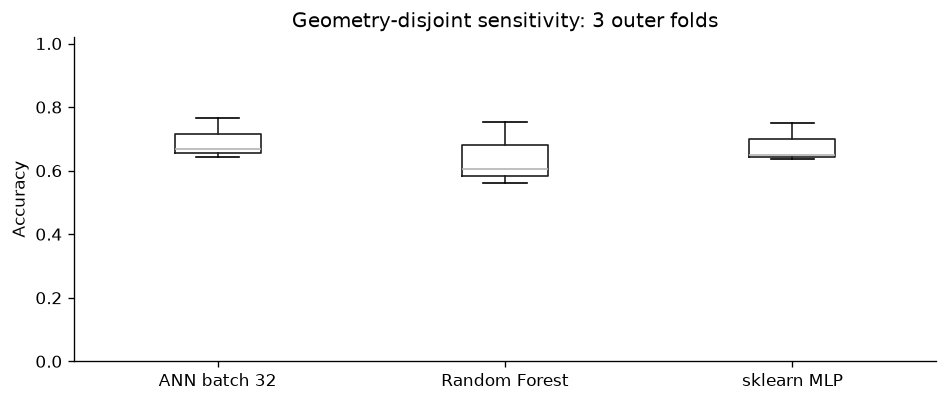

In [12]:
geometry_columns=['relative_compactness','surface_area','wall_area','roof_area','overall_height']
geometry_index=pd.MultiIndex.from_frame(X[geometry_columns])
groups=pd.Series(pd.factorize(geometry_index)[0],index=X.index)
overlap=len(set(groups.loc[development_ids]) & set(groups.loc[test_ids]))
print('Unique geometries:',groups.nunique(),'| PA2 development/test geometry overlap:',overlap)
stress=[]
for fold,(outer_train_pos,outer_test_pos) in enumerate(GroupKFold(n_splits=3).split(X,y,groups),1):
    outer_train_ids=X.index.to_numpy()[outer_train_pos]
    outer_test_ids=X.index.to_numpy()[outer_test_pos]
    inner_fit_pos,inner_val_pos=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(
        X.loc[outer_train_ids],y.loc[outer_train_ids],groups.loc[outer_train_ids]))
    inner_fit_ids=outer_train_ids[inner_fit_pos]; inner_val_ids=outer_train_ids[inner_val_pos]
    assert not (set(groups.loc[inner_fit_ids]) & set(groups.loc[outer_test_ids]))
    assert not (set(groups.loc[inner_fit_ids]) & set(groups.loc[inner_val_ids]))
    fixed={
        'Random Forest':RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=1),
        'sklearn MLP':MLPClassifier(hidden_layer_sizes=(64,32),alpha=.01,max_iter=800,
            early_stopping=True,n_iter_no_change=25,random_state=SEED)}
    fold_predictions=pd.DataFrame({'source_row_id':outer_test_ids,'truth':y.loc[outer_test_ids]})
    for name,est in fixed.items():
        pipe=Pipeline([('prepare',make_preprocessor()),('model',est)])
        pipe.fit(X.loc[inner_fit_ids],y.loc[inner_fit_ids])
        pred=pipe.predict(X.loc[outer_test_ids])
        stress.append({'fold':fold,'model':name,'accuracy':accuracy_score(y.loc[outer_test_ids],pred),
                       'weighted_f1':f1_score(y.loc[outer_test_ids],pred,average='weighted')})
        fold_predictions[name]=pred
    prep=make_preprocessor()
    a=prep.fit_transform(X.loc[inner_fit_ids]).astype('float32')
    v=prep.transform(X.loc[inner_val_ids]).astype('float32')
    t=prep.transform(X.loc[outer_test_ids]).astype('float32')
    network=build_ann(a.shape[1])
    network.fit(a,y.loc[inner_fit_ids].to_numpy(),validation_data=(v,y.loc[inner_val_ids].to_numpy()),
        epochs=50,batch_size=32,verbose=0,callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.5,patience=5)])
    pred=network.predict(t,verbose=0).argmax(axis=1)
    stress.append({'fold':fold,'model':'ANN batch 32','accuracy':accuracy_score(y.loc[outer_test_ids],pred),
                   'weighted_f1':f1_score(y.loc[outer_test_ids],pred,average='weighted')})
    fold_predictions['ANN batch 32']=pred
    fold_predictions.to_csv(OUT/f'geometry_fold{fold}_predictions.csv',index=False)
    print('Completed geometry stress fold',fold,'| fit/validation/test:',len(a),len(v),len(t))
stress=pd.DataFrame(stress)
stress.to_csv(OUT/'geometry_stress_folds.csv',index=False)
stress_summary=stress.groupby('model')[['accuracy','weighted_f1']].agg(['mean','std'])
stress_summary.to_csv(OUT/'geometry_stress_summary.csv')
display(stress_summary.round(4))
fig,ax=plt.subplots(figsize=(8,3.6))
stress.boxplot(column='accuracy',by='model',ax=ax,grid=False)
ax.set(title='Geometry-disjoint sensitivity: 3 outer folds',xlabel='',ylabel='Accuracy',ylim=(0,1.02))
plt.suptitle(''); fig.tight_layout(); savefig('06_geometry_stress.png')

## B.5 - Save and reload verification
Traditional .pkl files include preprocessing. Keras .h5 files require the separately
saved ann_preprocessor.pkl and the class order in model_metadata.json. Save every
training history as .pkl, plus CSV histories and native .keras checkpoints. Reopen
every deployed artifact and verify prediction equality. Pickle files should only be
loaded from a trusted source and with compatible package versions.

In [13]:
reload_checks={}
for name in traditional:
    with open(MODELS/(name.lower().replace(' ','_')+'.pkl'),'rb') as f: reloaded=pickle.load(f)
    np.testing.assert_allclose(reloaded.predict_proba(X_test),probabilities[name],atol=1e-8)
    reload_checks[name]=True
with open(MODELS/'ann_preprocessor.pkl','rb') as f: reloaded_prep=pickle.load(f)
np.testing.assert_allclose(reloaded_prep.transform(X_test).astype('float32'),A_test)
for batch in [16,32,64]:
    name='ANN batch '+str(batch)
    reloaded=keras.models.load_model(MODELS/f'ann_batch{batch}.h5',compile=False)
    np.testing.assert_allclose(reloaded.predict(A_test,verbose=0),probabilities[name],atol=1e-6)
    reload_checks[name]=True
metadata={'class_names':CLASS_NAMES,'class_boundaries':cutoffs.tolist(),'encoded_features':encoded_names,
    'source_features':feature_names,'source_sha256':digest,'versions':versions,
    'fit_rows':len(fit_ids),'validation_rows':len(val_ids),'test_rows':len(test_ids),
    'selected_traditional':best_traditional,'selected_ann':best_ann,
    'validation_selected_candidate':selected_by_validation,'observed_test_leader':observed_test_best,
    'geometry_count':int(groups.nunique()),'row_split_geometry_overlap':overlap,
    'paired_accuracy_interval':paired_ci.tolist(),'paired_mcnemar_p':float(paired_p),
    'majority_baseline_accuracy':baseline_accuracy,'reload_checks':reload_checks,
    'fitting_warnings':fitting_warnings,'student_verification':'pending',
    'authorship_status':'Substantial AI-generated reference; outside the brief whole-code restriction',
    'canvas_submission_performed':False,'github_publication_performed':False}
(MODELS/'model_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
(OUT/'analysis_manifest.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('All five model reload checks passed:',reload_checks)

All five model reload checks passed: {'Random Forest': True, 'sklearn MLP': True, 'ANN batch 16': True, 'ANN batch 32': True, 'ANN batch 64': True}


## C - Final summary and reflection
The following interpretation is generated from the executed results. It is assistant
analysis for student review, not a claim about what the student personally learned.

In [14]:
ml_acc=results.loc[best_traditional,'test_accuracy']; ann_acc=results.loc[best_ann,'test_accuracy']
delta=100*(ann_acc-ml_acc)
group_means=stress.groupby('model').accuracy.mean()
summary=f"""
### C.1 - Master results
The master table above contains both required traditional models and all three
ANN configurations, with accuracy, weighted/macro F1 and crossentropy on the same
231 rows. Traditional five-fold CV scores are reported separately from ANN validation.

### C.2 - Best model and deployment
**{best_traditional}** is the training-CV-selected traditional model. **{best_ann}**
has the lowest ANN validation loss. Their reused comparison-set accuracies are
**{ml_acc:.2%}** and **{ann_acc:.2%}**: ANN minus traditional is **{delta:+.2f} percentage
points**. The observed comparison-set leader is **{observed_test_best}**; the overall
candidate selected by validation accuracy (loss breaks ties) is **{selected_by_validation}**.
Selection criteria and observed test ranking answer different questions.

An ensemble can capture thresholds and interactions efficiently in a small tabular
dataset. A neural network learns smoother shared representations but needs optimisation
and regularisation. These mechanisms are plausible explanations, not experimentally
isolated causal claims. The paired row bootstrap interval for ANN minus traditional
is [{100*paired_ci[0]:.2f}, {100*paired_ci[1]:.2f}] percentage points, with exact paired
McNemar p={paired_p:.4f}. Reused rows and correlated geometries limit inference.

**Production deployment is not justified.** All {overlap} building geometries appear
on both sides of the inherited row split. Fixed-model geometry-disjoint mean accuracies
are RF {group_means['Random Forest']:.2%}, MLP {group_means['sklearn MLP']:.2%},
and ANN {group_means['ANN batch 32']:.2%}. These stress results concern unseen geometries,
whereas random row scores concern familiar geometry with different configurations.
The data are simulated, labels are relative terciles, and no external building-level
validation, calibration or monitoring has been completed.

### C.3 - Architecture, comparison and next steps
**Architecture choices:** Dense 64/32/16 layers learn nonlinear combinations; three
softmax outputs match the classes. Dropout 0.2 regularises both large hidden layers.
Changing batch size changes update frequency and gradient noise. Validation results
compare these batch sizes only; there is no no-dropout or width ablation, so the
experiment cannot attribute improvement specifically to dropout or depth. At epoch
10 the histories show early learning; the saved checkpoint uses the best validation
loss within at most 50 epochs rather than assuming that the final epoch is best.

**Did deep learning win?** The selected ANN's accuracy difference is {delta:+.2f}
percentage points on the reused row comparison. Compare probability loss and class
reports as well as accuracy. A single split cannot support a universal claim that
deep learning is superior; the scikit-learn MLP is also a neural network.

**With more time:** obtain independent real buildings and hold out complete geometries;
use nested grouped CV for tuning; repeat seeds; ablate dropout/width; check probability
calibration and ordinal errors near fixed cutoffs. If the practical objective is
continuous heating demand, compare regression with classification before operational
use. Engineer physically meaningful ratios only inside validated pipelines and assess
their incremental value rather than including Y1 or Y2 as predictors.
"""
display(Markdown(summary))
(OUT/'interpretation.md').write_text(summary,encoding='utf-8')


### C.1 - Master results
The master table above contains both required traditional models and all three
ANN configurations, with accuracy, weighted/macro F1 and crossentropy on the same
231 rows. Traditional five-fold CV scores are reported separately from ANN validation.

### C.2 - Best model and deployment
**Random Forest** is the training-CV-selected traditional model. **ANN batch 16**
has the lowest ANN validation loss. Their reused comparison-set accuracies are
**93.07%** and **86.15%**: ANN minus traditional is **-6.93 percentage
points**. The observed comparison-set leader is **Random Forest**; the overall
candidate selected by validation accuracy (loss breaks ties) is **Random Forest**.
Selection criteria and observed test ranking answer different questions.

An ensemble can capture thresholds and interactions efficiently in a small tabular
dataset. A neural network learns smoother shared representations but needs optimisation
and regularisation. These mechanisms are plausible explanations, not experimentally
isolated causal claims. The paired row bootstrap interval for ANN minus traditional
is [-11.69, -2.16] percentage points, with exact paired
McNemar p=0.0090. Reused rows and correlated geometries limit inference.

**Production deployment is not justified.** All 12 building geometries appear
on both sides of the inherited row split. Fixed-model geometry-disjoint mean accuracies
are RF 64.06%, MLP 67.84%,
and ANN 69.27%. These stress results concern unseen geometries,
whereas random row scores concern familiar geometry with different configurations.
The data are simulated, labels are relative terciles, and no external building-level
validation, calibration or monitoring has been completed.

### C.3 - Architecture, comparison and next steps
**Architecture choices:** Dense 64/32/16 layers learn nonlinear combinations; three
softmax outputs match the classes. Dropout 0.2 regularises both large hidden layers.
Changing batch size changes update frequency and gradient noise. Validation results
compare these batch sizes only; there is no no-dropout or width ablation, so the
experiment cannot attribute improvement specifically to dropout or depth. At epoch
10 the histories show early learning; the saved checkpoint uses the best validation
loss within at most 50 epochs rather than assuming that the final epoch is best.

**Did deep learning win?** The selected ANN's accuracy difference is -6.93
percentage points on the reused row comparison. Compare probability loss and class
reports as well as accuracy. A single split cannot support a universal claim that
deep learning is superior; the scikit-learn MLP is also a neural network.

**With more time:** obtain independent real buildings and hold out complete geometries;
use nested grouped CV for tuning; repeat seeds; ablate dropout/width; check probability
calibration and ordinal errors near fixed cutoffs. If the practical objective is
continuous heating demand, compare regression with classification before operational
use. Engineer physically meaningful ratios only inside validated pipelines and assess
their incremental value rather than including Y1 or Y2 as predictors.


3178

## D - Repository and reproducibility
The complete Assessment 3 files are in [portfolio/assessment-3](https://github.com/odmiefnf/COS40007/tree/main/portfolio/assessment-3) on the main
branch of [https://github.com/odmiefnf/COS40007](https://github.com/odmiefnf/COS40007), the same repository as Portfolio 1 and 2. The repository
contains the executed notebook, source data, saved models, histories, metrics, figures,
PDF and reproducibility scripts. Real local development milestones are retained in
the integration history with OpenAI Codex attribution; no backdating or student-authorship
claim is made. No Canvas submission has been performed.

Historical execution note: code outputs and model metadata were recorded before
GitHub publication. Their publication flags describe that analysis run. The subsequent
publication is recorded separately in output/github_publication_receipt.json. No
analysis code, predictions, model weights or recorded outputs were changed to add links.

## References
1. Tsanas, A. and Xifara, A. (2012). Energy Efficiency [Dataset]. UCI Machine Learning
Repository. https://doi.org/10.24432/C51307 . CC BY 4.0.
2. Swinburne Canvas. Portfolio Assessment 3, course 78034, assignment 803620;
option 3d brief, accessed 2 November 2026.
https://swinburne.instructure.com/courses/78034/assignments/803620 .
3. Scikit-learn. RandomForestClassifier API.
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html .
4. Scikit-learn. Neural network models (supervised).
https://scikit-learn.org/stable/modules/neural_networks_supervised.html .
5. Keras. Training and evaluation with built-in methods.
https://keras.io/guides/training_with_built_in_methods/ .
6. Keras. ModelCheckpoint and callbacks.
https://keras.io/api/callbacks/model_checkpoint/ and https://keras.io/api/callbacks/ .

The mandatory GenAI reflection appears in the PDF report, using the supplied four-part
template. GENAI_EVIDENCE.md separately records provenance. Neither asserts independent
student authorship or completed student learning.